Name: Sana Raza

Labpartner(s)

In [21]:
#import statements go here

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import matplotlib.image as mpimg
from IPython.display import Image
import pandas as pd

# Class 7.2

Today your assignment is the rest of the pandas unit and to catch up and think about your project topic, which is due by Sunday 10/13.

**W.1** Implement a function that takes as input three variables, and returns the largest of the three. Do this without using the Python max() function.

The goal of this exercise is to think about some internals that Python normally takes care of for us. All you need is some variables and if statements.

In [71]:
def large_number():
  num1 = int(input("Enter the first number: "))
  num2 = int(input("Enter the second number: "))
  num3 = int(input("Enter the third number: "))

  if num1 >= num2 and num1 >= num3:
    print("Num1 is the largest:", num1)
  elif num2 >= num1 and num2 >= num3:
    print("Num2 is the largest:", num2)
  else:
    print("Num3 is the largest:", num3)


# now calling the function!

large_number()

Enter the first number:  2
Enter the second number:  3
Enter the third number:  6


Num3 is the largest: 6


# Lecture 7.2

### Agenda:

- Questions
- Tropical Tidbits
- Movie project!

### Questions

For our project this week, I am unleashing you use LLMs for coding, and specifically how to make a series of images into a playable movie. For example, say you have a series of daily HYCOM SST plots, and you want to animate this, how would you do it? We'll strategize more in class about how to accomplish this as a team and with the help of ChatGPT, Claude, or whatever, and hopefully come up with a few different workflows you can share. 

# Lab 7.2

**E.0** Complete the previous labs if you are behind.

**E.1** Complete Data Manipulation with Pandas Ch 3-4 in datacamp.

**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# A tiny made-up dataset (not real measurements) so every example below actually runs.
# One value is missing (NaN) on purpose, to practice handling missing data in Chapter 4.
temps = pd.DataFrame({
    "date": pd.to_datetime(["2024-01-01", "2024-07-01", "2025-01-01", "2025-07-01",
                            "2024-01-01", "2024-07-01", "2025-01-01", "2025-07-01"]),
    "city": ["Karachi", "Karachi", "Karachi", "Karachi",
             "Baton Rouge", "Baton Rouge", "Baton Rouge", "Baton Rouge"],
    "country": ["Pakistan"] * 4 + ["USA"] * 4,
    "avg_temp": [18.5, 31.0, 19.2, np.nan, 10.4, 28.1, 11.0, 28.6],
})
temps

,date,city,country,avg_temp
0,2024-01-01,Karachi,Pakistan,18.5
1,2024-07-01,Karachi,Pakistan,31.0
2,2025-01-01,Karachi,Pakistan,19.2
3,2025-07-01,Karachi,Pakistan,NaN
4,2024-01-01,Baton Rouge,USA,10.4
5,2024-07-01,Baton Rouge,USA,28.1
6,2025-01-01,Baton Rouge,USA,11.0
7,2025-07-01,Baton Rouge,USA,28.6


In [73]:
# An index is like a "row name". Here I make the city column the index.
temps_city = temps.set_index("city")
print(temps_city.head())

# reset_index() undoes it and turns the index back into a normal column
print(temps_city.reset_index().head())

# reset_index(drop=True) throws the index away completely
print(temps_city.reset_index(drop=True).head())

                  date   country  avg_temp
city                                      
Karachi     2024-01-01  Pakistan      18.5
Karachi     2024-07-01  Pakistan      31.0
Karachi     2025-01-01  Pakistan      19.2
Karachi     2025-07-01  Pakistan       NaN
Baton Rouge 2024-01-01       USA      10.4
          city       date   country  avg_temp
0      Karachi 2024-01-01  Pakistan      18.5
1      Karachi 2024-07-01  Pakistan      31.0
2      Karachi 2025-01-01  Pakistan      19.2
3      Karachi 2025-07-01  Pakistan       NaN
4  Baton Rouge 2024-01-01       USA      10.4
        date   country  avg_temp
0 2024-01-01  Pakistan      18.5
1 2024-07-01  Pakistan      31.0
2 2025-01-01  Pakistan      19.2
3 2025-07-01  Pakistan       NaN
4 2024-01-01       USA      10.4


In [74]:
# With city as the index, I can grab rows by name, which is shorter than filtering
print(temps_city.loc["Karachi"])

# a list of names gets several cities at once
print(temps_city.loc[["Karachi", "Baton Rouge"]])

              date   country  avg_temp
city                                  
Karachi 2024-01-01  Pakistan      18.5
Karachi 2024-07-01  Pakistan      31.0
Karachi 2025-01-01  Pakistan      19.2
Karachi 2025-07-01  Pakistan       NaN
                  date   country  avg_temp
city                                      
Karachi     2024-01-01  Pakistan      18.5
Karachi     2024-07-01  Pakistan      31.0
Karachi     2025-01-01  Pakistan      19.2
Karachi     2025-07-01  Pakistan       NaN
Baton Rouge 2024-01-01       USA      10.4
Baton Rouge 2024-07-01       USA      28.1
Baton Rouge 2025-01-01       USA      11.0
Baton Rouge 2025-07-01       USA      28.6


In [75]:
# The index can have more than one level, here country first and then city inside it
temps_cc = temps.set_index(["country", "city"])
print(temps_cc)

# to pick a row from the inner level I pass a tuple: (outer, inner)
print(temps_cc.loc[("Pakistan", "Karachi")])

                           date  avg_temp
country  city                            
Pakistan Karachi     2024-01-01      18.5
         Karachi     2024-07-01      31.0
         Karachi     2025-01-01      19.2
         Karachi     2025-07-01       NaN
USA      Baton Rouge 2024-01-01      10.4
         Baton Rouge 2024-07-01      28.1
         Baton Rouge 2025-01-01      11.0
         Baton Rouge 2025-07-01      28.6
                       date  avg_temp
country  city                        
Pakistan Karachi 2024-01-01      18.5
         Karachi 2024-07-01      31.0
         Karachi 2025-01-01      19.2
         Karachi 2025-07-01       NaN


In [76]:
# sort_index() sorts the rows by the index values (alphabetically here)
print(temps_cc.sort_index())

# I can choose which level to sort by and the direction
print(temps_cc.sort_index(level="city", ascending=False))

                           date  avg_temp
country  city                            
Pakistan Karachi     2024-01-01      18.5
         Karachi     2024-07-01      31.0
         Karachi     2025-01-01      19.2
         Karachi     2025-07-01       NaN
USA      Baton Rouge 2024-01-01      10.4
         Baton Rouge 2024-07-01      28.1
         Baton Rouge 2025-01-01      11.0
         Baton Rouge 2025-07-01      28.6
                           date  avg_temp
country  city                            
Pakistan Karachi     2024-01-01      18.5
         Karachi     2024-07-01      31.0
         Karachi     2025-01-01      19.2
         Karachi     2025-07-01       NaN
USA      Baton Rouge 2024-01-01      10.4
         Baton Rouge 2024-07-01      28.1
         Baton Rouge 2025-01-01      11.0
         Baton Rouge 2025-07-01      28.6


In [77]:
# Important: the index has to be sorted before slicing, or pandas complains
temps_srt = temps_cc.sort_index()

# slice the outer level from "Pakistan" to "USA" (the end is included with .loc)
print(temps_srt.loc["Pakistan":"USA"])

# slicing the inner level needs tuples for the start and end
print(temps_srt.loc[("Pakistan", "Karachi"):("USA", "Baton Rouge")])

# slicing columns too: all rows, columns from "date" to "avg_temp"
print(temps_srt.loc[:, "date":"avg_temp"])

                           date  avg_temp
country  city                            
Pakistan Karachi     2024-01-01      18.5
         Karachi     2024-07-01      31.0
         Karachi     2025-01-01      19.2
         Karachi     2025-07-01       NaN
USA      Baton Rouge 2024-01-01      10.4
         Baton Rouge 2024-07-01      28.1
         Baton Rouge 2025-01-01      11.0
         Baton Rouge 2025-07-01      28.6
                           date  avg_temp
country  city                            
Pakistan Karachi     2024-01-01      18.5
         Karachi     2024-07-01      31.0
         Karachi     2025-01-01      19.2
         Karachi     2025-07-01       NaN
USA      Baton Rouge 2024-01-01      10.4
         Baton Rouge 2024-07-01      28.1
         Baton Rouge 2025-01-01      11.0
         Baton Rouge 2025-07-01      28.6
                           date  avg_temp
country  city                            
Pakistan Karachi     2024-01-01      18.5
         Karachi     2024-07-01   

In [78]:
# With dates as the index, I can slice using just part of a date
temps_date = temps.set_index("date").sort_index()

# everything from 2024
print(temps_date.loc["2024":"2024"])

# from June 2024 to February 2025
print(temps_date.loc["2024-06":"2025-02"])

                   city   country  avg_temp
date                                       
2024-01-01      Karachi  Pakistan      18.5
2024-01-01  Baton Rouge       USA      10.4
2024-07-01      Karachi  Pakistan      31.0
2024-07-01  Baton Rouge       USA      28.1
                   city   country  avg_temp
date                                       
2024-07-01      Karachi  Pakistan      31.0
2024-07-01  Baton Rouge       USA      28.1
2025-01-01      Karachi  Pakistan      19.2
2025-01-01  Baton Rouge       USA      11.0


In [79]:
# make a year column from the date first
temps["year"] = temps["date"].dt.year

# pivot table: one row per city, one column per year, mean temperature in the cells
pivot = temps.pivot_table(values="avg_temp", index="city", columns="year")
print(pivot)

# a pivot table is just a DataFrame, so .loc works on it too
print(pivot.loc["Karachi"])    # one row
print(pivot.loc[:, 2025])      # one column

# calculating across it:
print(pivot.mean(axis="index"))     # mean of each column (each year, across cities)
print(pivot.mean(axis="columns"))   # mean of each row (each city, across years)

year          2024  2025
city                    
Baton Rouge  19.25  19.8
Karachi      24.75  19.2
year
2024    24.75
2025    19.20
Name: Karachi, dtype: float64
city
Baton Rouge    19.8
Karachi        19.2
Name: 2025, dtype: float64
year
2024    22.0
2025    19.5
dtype: float64
city
Baton Rouge    19.525
Karachi        21.975
dtype: float64


**E.3** For this week's project, find a series of images you want to animate. This can be model output, a series of other plots, whatever you want. Everyone needs to pick their own dataset. Work together and share ideas for different ways to make these movies, and work with an LLM to help you figure this out. Next week on Monday or Wednesday you will present your movie and tell us how you made it.

In [80]:
import matplotlib.image as mpimg        # to read my saved PNG frames back in
from matplotlib.animation import FuncAnimation, PillowWriter   # to turn many plots into a GIF
from IPython.display import Image       # to show the GIF inside the notebook

In [81]:
# I want a black background for all my plots, it makes the colors pop
plt.style.use("dark_background")

# The settings for my birth-death simulation
birth_rate = 1.0   # how often a lineage splits into two (speciation)
death_rate = 0.3   # how often a lineage dies out (extinction)
max_time   = 5.0   # how long I let the tree grow

In [82]:
# This function grows one phylogenetic tree forward in time
def simulate_tree(birth_rate, death_rate, max_time, seed):
    # random number generator; using a seed means I get the same tree every time I run it
    rng = np.random.default_rng(seed)

    # I keep every lineage as a dictionary: when it started, when it ended,
    # who its parent is, its children, and whether it went extinct.
    # The tree starts with just one lineage (the root) at time 0.
    lineages = [{"start": 0.0, "end": None, "parent": None, "children": [], "extinct": False}]

    # list of lineages that are alive right now (only the root at the start)
    alive = [0]
    t = 0.0

    # keep going as long as something is still alive
    while alive:
        # the more lineages are alive, the sooner the next event happens
        total_rate = len(alive) * (birth_rate + death_rate)

        # jump forward to the time of the next event
        t = t + rng.exponential(1 / total_rate)

        # stop once we pass the end of the simulation
        if t > max_time:
            break

        # pick one of the living lineages at random, the event happens to this one
        who = rng.choice(alive)
        alive.remove(who)
        lineages[who]["end"] = t   # either way, this lineage ends here

        # decide if it's a speciation or an extinction
        if rng.random() < birth_rate / (birth_rate + death_rate):
            # speciation: the lineage splits and two new daughter lineages start
            for _ in range(2):
                lineages.append({"start": t, "end": None, "parent": who, "children": [], "extinct": False})
                lineages[who]["children"].append(len(lineages) - 1)   # remember the daughter
                alive.append(len(lineages) - 1)                       # the daughter is alive now
        else:
            # extinction: the lineage just dies out
            lineages[who]["extinct"] = True

    # anything still alive at the end gets its end time set to max_time
    for lin in lineages:
        if lin["end"] is None:
            lin["end"] = max_time

    # give back the full history of the tree
    return lineages

In [83]:
# Some trees die out or end up tiny, so I try different seeds
# until I get a tree with a nice size (between 150 and 400 lineages)
seed = 0
while True:
    lineages = simulate_tree(birth_rate, death_rate, max_time, seed)
    if 150 <= len(lineages) <= 400:
        break       # found a good tree, stop looking
    seed += 1       # otherwise try the next seed

print("seed", seed, "lineages", len(lineages))

# Now I need to decide where each lineage goes in the picture.
# The tips get positions 0, 1, 2, ... and each parent sits halfway between its two children.
counter = [0]   # keeps track of the next free position for a tip

def set_y(i):
    lin = lineages[i]
    if lin["children"]:
        # first place the children, then put the parent in the middle of them
        ys = [set_y(c) for c in lin["children"]]
        lin["y"] = sum(ys) / len(ys)
    else:
        # this is a tip, so it just takes the next free position
        lin["y"] = counter[0]
        counter[0] += 1
    return lin["y"]

set_y(0)              # start from the root and it works its way through the whole tree
n_tips = counter[0]   # total number of tips

# Since I'm drawing the tree as a circle, I turn each position into an angle.
# I only use 350 degrees so there is a small gap and the first and last clades don't touch.
for lin in lineages:
    lin["angle"] = lin["y"] / n_tips * np.radians(350)

seed 2 lineages 301


In [84]:
# Turning my simulated tree into an actual dataset, one row per lineage
rows = []
for i, lin in enumerate(lineages):
    rows.append({
        "lineage_id": i,                          # the number of the lineage
        "parent_id":  lin["parent"],              # which lineage it came from
        "start_time": round(lin["start"], 4),     # when it appeared
        "end_time":   round(lin["end"], 4),       # when it split, died, or the simulation ended
        "extinct":    lin["extinct"],             # True if it died out
        "speciated":  len(lin["children"]) > 0,   # True if it split into two
    })

# make it a pandas table and save it as a CSV file
tree_data = pd.DataFrame(rows)
tree_data.to_csv("simulated_tree.csv", index=False)

# quick summary: .sum() counts how many True values there are
print(tree_data["extinct"].sum(), "extinctions")
print(tree_data["speciated"].sum(), "speciation events")

# peek at the first few rows
tree_data.head()

35 extinctions
150 speciation events


,lineage_id,parent_id,start_time,end_time,extinct,speciated
0,0,NaN,0.0000,0.0999,False,True
1,1,0.0,0.0999,0.2974,False,True
2,2,0.0,0.0999,0.6409,False,True
3,3,1.0,0.2974,3.3508,True,False
4,4,1.0,0.2974,0.9588,False,True


In [85]:
# rainbow colormap so different parts of the tree get different colors
colormap = plt.cm.turbo

# This draws the tree the way it looks at time t, so it's one frame of the movie
def draw_frame(t):
    ax.clear()   # wipe the previous frame

    for lin in lineages:
        # skip lineages that haven't appeared yet
        if lin["start"] > t:
            continue

        # only draw the branch up to the current time, so it looks like it's growing
        end = min(lin["end"], t)

        # a lineage counts as dead only once its extinction has actually happened
        dead = lin["extinct"] and lin["end"] <= t

        # dead branches are grey, living ones get a color based on where they sit in the circle
        color = "0.45" if dead else colormap(lin["angle"] / np.radians(350))

        # the branch itself: same angle, going outward from start time to end time
        ax.plot([lin["angle"], lin["angle"]], [lin["start"], end], color=color, linewidth=1.3)

        # put a small x where a lineage went extinct
        if dead:
            ax.plot(lin["angle"], lin["end"], "x", color="0.6", markersize=4)

        # if this lineage already split, draw the curved line that joins its two daughters
        if lin["children"] and lin["end"] <= t:
            a = [lineages[c]["angle"] for c in lin["children"]]
            arc = np.linspace(min(a), max(a), 30)   # 30 points make the curve smooth
            ax.plot(arc, [lin["end"]] * 30, color=colormap(lin["angle"] / np.radians(350)), linewidth=1.3)

            # little white flash right after a split happens
            if t - lin["end"] < 0.15:
                ax.plot(lin["angle"], lin["end"], "o", color="white", markersize=6)

    # count how many lineages are alive at this moment
    # (the ones that survived to the very end also count in the last frame)
    n_alive = sum(1 for lin in lineages
                  if lin["start"] <= t and (lin["end"] > t or
                     (lin["end"] == max_time and not lin["extinct"] and not lin["children"])))

    ax.set_ylim(0, max_time)   # keep the size of the circle the same in every frame
    ax.axis("off")             # hide the grid and numbers
    ax.set_title(f"A tree of life growing\ntime = {t:.2f}   lineages alive = {n_alive}",
                 color="white", fontsize=13)

In [86]:
# Saving three moments of the tree as separate pictures (early, middle, end)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})   # polar = round plot

for t in [1.5, 3.0, 5.0]:
    draw_frame(t)                              # draw the tree at this time
    fig.savefig(f"frame_t{t}.png", dpi=150)    # save it as a PNG

plt.close(fig)   # I don't need to display this figure here

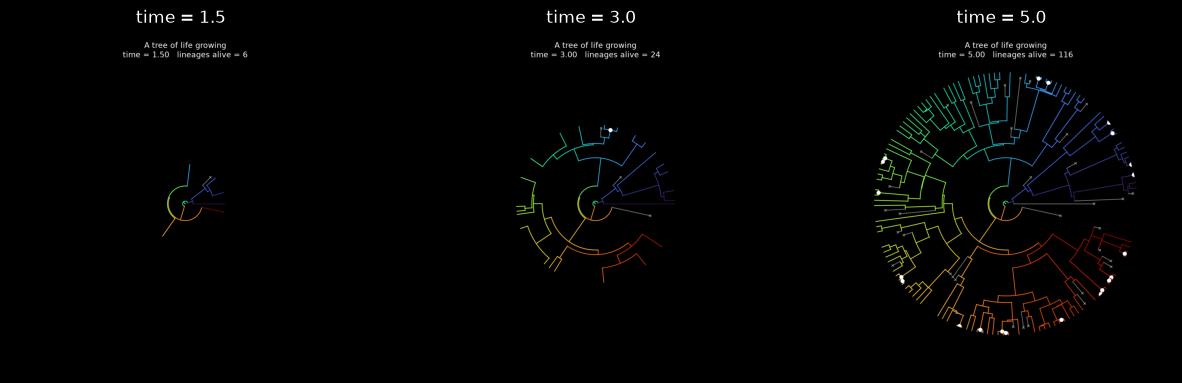

In [87]:
# Showing the three saved pictures next to each other, like a timeline
fig2, panels = plt.subplots(1, 3, figsize=(15, 5))   # 1 row, 3 panels

for panel, t in zip(panels, [1.5, 3.0, 5.0]):
    panel.imshow(mpimg.imread(f"frame_t{t}.png"))    # load the picture and show it
    panel.set_title(f"time = {t}")
    panel.axis("off")

plt.show()

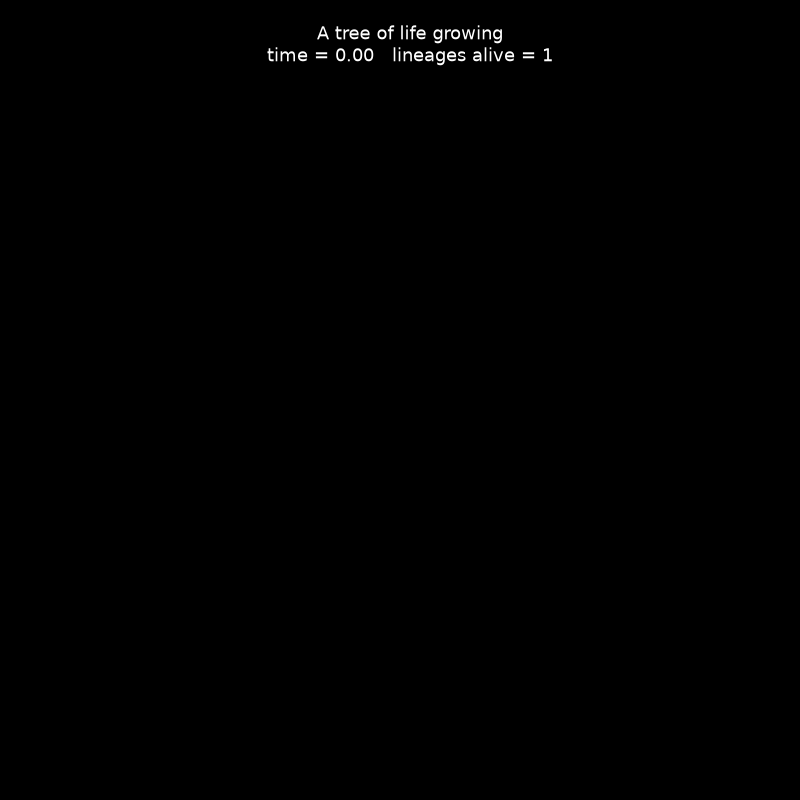

In [88]:
# round figure for the movie
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})

# 100 time points from 0 to max_time, and each one becomes one frame
times = np.linspace(0, max_time, 100)

# FuncAnimation calls draw_frame() for every time point and collects the frames
movie = FuncAnimation(fig, draw_frame, frames=times)

# save all the frames together as a GIF (12 frames per second, so about 8 seconds)
movie.save("fan_tree.gif", writer=PillowWriter(fps=12))
plt.close(fig)

Image("fan_tree.gif")

![Tree growing](https://raw.githubusercontent.com/chsharrison/Sci_comp_F26/main/Sana_Raza/fan_tree.gif)

In [89]:
# For the second movie I want to know which lineages left someone alive today.
# A tip "survives" if it didn't go extinct, and a parent survives if any of its children survive.
def has_survivors(i):
    lin = lineages[i]
    if lin["children"]:
        lin["survives"] = any([has_survivors(c) for c in lin["children"]])
    else:
        lin["survives"] = not lin["extinct"]
    return lin["survives"]

has_survivors(0)   # start from the root and check the whole tree

# How much of the tree's history would we never see if we only had living species?
# I compare the length of the "lost" branches to the total length of all branches.
total_length  = sum(lin["end"] - lin["start"] for lin in lineages)
hidden_length = sum(lin["end"] - lin["start"] for lin in lineages if not lin["survives"])
percent_hidden = 100 * hidden_length / total_length
print(f"{percent_hidden:.1f}% of the history is hidden")

14.7% of the history is hidden


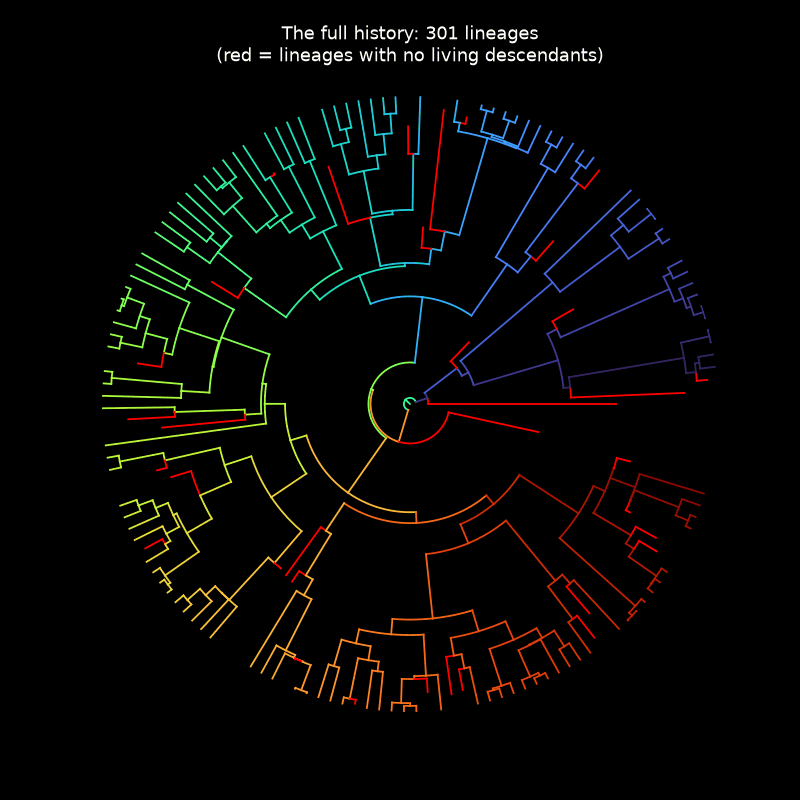

In [90]:
# Fresh round figure for the second movie
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})

# fade = 1 shows the full tree with the lost lineages in red,
# fade = 0 shows only the lineages that lead to living species
def draw_pruning(fade):
    ax.clear()

    for lin in lineages:
        color = colormap(lin["angle"] / np.radians(350))

        # branches that lead to living species always stay in color
        if lin["survives"]:
            ax.plot([lin["angle"], lin["angle"]], [lin["start"], lin["end"]], color=color, linewidth=1.3)
        # lost branches are red and get more see-through as fade goes down
        elif fade > 0:
            ax.plot([lin["angle"], lin["angle"]], [lin["start"], lin["end"]], color="red", alpha=fade, linewidth=1.3)

        # curved line from the parent to each daughter, so the tree stays connected
        for c in lin["children"]:
            arc = np.linspace(lin["angle"], lineages[c]["angle"], 20)
            if lineages[c]["survives"]:
                ax.plot(arc, [lin["end"]] * 20, color=color, linewidth=1.3)
            elif fade > 0:
                ax.plot(arc, [lin["end"]] * 20, color="red", alpha=fade, linewidth=1.3)

    ax.set_ylim(0, max_time)
    ax.axis("off")

    # title changes halfway through the fading
    if fade > 0.5:
        title = f"The full history: {len(lineages)} lineages\n(red = lineages with no living descendants)"
    else:
        title = f"What we can see from living species only\n{percent_hidden:.0f}% of the history is hidden"
    ax.set_title(title, color="white", fontsize=13)

# frames for the movie: 15 frames of the full tree, 50 frames of fading,
# then 20 frames of the final tree so people have time to read it
fades = np.concatenate([np.ones(15), np.linspace(1, 0, 50), np.zeros(20)])

movie2 = FuncAnimation(fig, draw_pruning, frames=fades)
movie2.save("pruned_tree.gif", writer=PillowWriter(fps=12))
plt.close(fig)

# show the second movie in the notebook
Image("pruned_tree.gif")

![Hidden history](https://raw.githubusercontent.com/chsharrison/Sci_comp_F26/main/Sana_Raza/pruned_tree.gif)